# ¿Puede una IA diseñar un péptido que acierte a dos dianas a la vez?

**Diseñando para dos dianas a la vez, el método de partida acertaba en 5,5 de cada 100 intentos. ORIDTP acierta en 56,6.** Y los péptidos que salieron no se quedaron en la pantalla: el mejor bajó el peso de ratones obesos un 26,0 % en tres semanas, y en un problema completamente distinto —dos frenos del sistema inmune— otro encogió el tumor de ratones un 94,2 % frente al control.

**Paper:** Lv et al. (2026). *De novo design of high-potency dual-target therapeutic peptides with ORIDTP*. **Nature**.
**DOI:** [10.1038/s41586-026-11338-1](https://doi.org/10.1038/s41586-026-11338-1)

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ciencia-a-Mordiscos/lab/blob/main/papers/2026-11-26-peptidos-dual-target-ia/notebook.ipynb)

**Video:** Pendiente

Un péptido es una cadena corta de aminoácidos: más pequeño que una proteína, más grande que un fármaco clásico. Diseñar uno que se pegue fuerte a **un** receptor ya es difícil; que se pegue fuerte a **dos** receptores distintos, con la misma secuencia, es un problema aparte — cada cambio que mejora un acoplamiento suele empeorar el otro.

El equipo construyó ORIDTP, una plataforma de IA que ataca justo eso: primero aprende de los diseños de una sola diana (transferencia de conocimiento) y después refuerza la búsqueda premiando las secuencias que funcionan en **ambas** dianas a la vez. Lo probaron en dos parejas de dianas que no tienen nada que ver entre sí:

- **GLP-1R y GCGR**, los receptores del GLP-1 y del glucagón. Es el terreno de la semaglutida y la mazdutida, los fármacos de obesidad y diabetes tipo 2.
- **PD-1 y CTLA-4**, dos frenos que los tumores usan para apagar la respuesta inmune. Aquí ORIDTP diseñó *sin reentrenar* (lo que en IA se llama *zero-shot*).

Vamos a abrir los datos crudos que el paper publica con su mismo DOI: el **Source Data** de las figuras 2 a 5 y las tablas del **material suplementario**. Con eso se puede rehacer casi todo: el filtro computacional, las potencias medidas en células, y los experimentos en animales.

⚠️ **Todo lo que sigue pasa en ratones, ratas y células.** No hay ensayos clínicos: ni pacientes, ni humanos sanos. Las dosis, los pesos y los tumores son de roedores.

In [1]:
# ══════════════════════════════════════════════════════════════
# Configuración — modifica estos valores para explorar
# ══════════════════════════════════════════════════════════════
DOSIS_GA_DUAL = '1.5'    # dosis de GA-Dual.R5.S3 a destacar: '0.5', '1.0' o '1.5' nmol/kg
DIA_FINAL_DIO = 21       # día del experimento en ratones obesos (0, 7, 14 o 21)
DIA_FINAL_TUMOR = 24     # día del experimento de tumor (0 a 24, cada 3)
FUENTE = 'Fuente: Lv et al. (2026), Nature | Datos: Source Data y Supplementary Information del mismo DOI'
COLOR_DATOS = '#2563EB'
COLOR_ALERTA = '#DC2626'
COLOR_REFERENCIA = '#D97706'
COLOR_SEC = '#059669'
COLOR_VIOLETA = '#7C3AED'
COLOR_GRIS = '#BBBBBB'

import os, re, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from scipy import stats

BASE = 'https://raw.githubusercontent.com/Ciencia-a-Mordiscos/lab/main/papers/2026-11-26-peptidos-dual-target-ia'
ARCHIVOS = ['hit_rate_benchmark.csv', 'metricas_resumen.csv', 'ec50_peptidos.csv', 'bioactividad_rondas.csv',
            'peso_corporal_dio.csv', 'ingesta_dio.csv', 'glucosa_basal_dio.csv', 'homa_ir_dio.csv',
            'aversion_sacarina.csv', 'kaolin_pica.csv', 'inhibicion_checkpoints.csv', 'tumor_doble_ki.csv']
os.makedirs('datos', exist_ok=True)
os.makedirs('figuras', exist_ok=True)
for a in ARCHIVOS:
    if not os.path.exists(f'datos/{a}'):
        urllib.request.urlretrieve(f'{BASE}/datos/{a}', f'datos/{a}')

style_file = '../../cam.mplstyle'
if not os.path.exists(style_file):
    style_file = '/tmp/cam.mplstyle'
    if not os.path.exists(style_file):
        urllib.request.urlretrieve('https://raw.githubusercontent.com/Ciencia-a-Mordiscos/lab/main/cam.mplstyle', style_file)
plt.style.use(style_file)

# Números en formato español: coma decimal, punto de miles, signo menos tipográfico
def es(x):
    s = str(x)
    s = re.sub(r'(\d)[eE]\+?(-?)0*(\d+)', r'\1×10^\2\3', s)   # notación científica
    s = re.sub(r'(?<=\d),(?=\d{3}(?!\d))', '_', s)   # separador de miles
    s = re.sub(r'(?<=\d)\.(?=\d)', ',', s)
    s = re.sub(r'(?<![\w,])-(?=\d)', '−', s)
    return s.replace('_', '.')

def pr(*a):
    print(*[es(x) for x in a])

COMA = FuncFormatter(lambda v, _: es(f'{v:g}'))

# Cohen's d con SD agrupada (grupos independientes: ninguna medida está pareada entre días o grupos)
def cohen_d(a, b):
    na, nb = len(a), len(b)
    sd = np.sqrt(((na - 1) * np.var(a, ddof=1) + (nb - 1) * np.var(b, ddof=1)) / (na + nb - 2))
    return (np.mean(a) - np.mean(b)) / sd

def mw(a, b):
    return stats.mannwhitneyu(a, b).pvalue

# ── Carga ──
hit = pd.read_csv('datos/hit_rate_benchmark.csv')
metricas = pd.read_csv('datos/metricas_resumen.csv')
ec50 = pd.read_csv('datos/ec50_peptidos.csv')
folds_fig = pd.read_csv('datos/bioactividad_rondas.csv')
peso = pd.read_csv('datos/peso_corporal_dio.csv')
ingesta = pd.read_csv('datos/ingesta_dio.csv')
glucosa = pd.read_csv('datos/glucosa_basal_dio.csv')
homa = pd.read_csv('datos/homa_ir_dio.csv')
sacarina = pd.read_csv('datos/aversion_sacarina.csv')
kaolin = pd.read_csv('datos/kaolin_pica.csv')
inhib = pd.read_csv('datos/inhibicion_checkpoints.csv')
tumor = pd.read_csv('datos/tumor_doble_ki.csv')

GA = f'GA-Dual.R5.S3 ({DOSIS_GA_DUAL} nmol/kg)'
CORTO = {'GA-Dual.R5.S3 (0.5 nmol/kg)': 'GA-Dual\n0,5', 'GA-Dual.R5.S3 (1.0 nmol/kg)': 'GA-Dual\n1,0',
         'GA-Dual.R5.S3 (1.5 nmol/kg)': 'GA-Dual\n1,5', 'Mazdutide (15.0 nmol/kg)': 'Mazdutida\n15,0',
         'Semaglutide (15.0 nmol/kg)': 'Semaglutida\n15,0', 'Vehicle': 'Vehículo'}
COLOR = {'GA-Dual.R5.S3 (0.5 nmol/kg)': '#A5B4FC', 'GA-Dual.R5.S3 (1.0 nmol/kg)': '#60A5FA',
         'GA-Dual.R5.S3 (1.5 nmol/kg)': COLOR_DATOS, 'Mazdutide (15.0 nmol/kg)': COLOR_REFERENCIA,
         'Semaglutide (15.0 nmol/kg)': COLOR_VIOLETA, 'Vehicle': COLOR_GRIS}

pr('Benchmark computacional:', len(hit), 'filas —', hit.benchmark.nunique(), 'regímenes ×', hit.metodo.nunique(), 'métodos')
pr('Péptidos GLP-1R/GCGR medidos:', len(ec50), 'en', ec50.ronda.nunique(), 'rondas de diseño')
pr('Ratones obesos (DIO):', peso.groupby('tratamiento').dia.count().min() // peso.dia.nunique(), 'por grupo ×',
   peso.tratamiento.nunique(), 'grupos, días', [int(d) for d in sorted(peso.dia.unique())])
pr('Ratones con tumor (doble knock-in):', len(tumor[tumor.dia == 0]) // tumor.tratamiento.nunique(), 'por grupo ×',
   tumor.tratamiento.nunique(), 'grupos, días 0 a', tumor.dia.max())
pr('Curvas de inhibición in vitro:', len(inhib), 'puntos —', inhib.interaccion.nunique(), 'interacciones ×',
   inhib.tratamiento.nunique(), 'tratamientos (3 réplicas por concentración)')
pr('Dosis destacada de GA-Dual.R5.S3:', DOSIS_GA_DUAL, 'nmol/kg · comparadores: 15,0 nmol/kg (×10 más)')

Benchmark computacional: 10 filas — 2 regímenes × 5 métodos
Péptidos GLP-1R/GCGR medidos: 20 en 5 rondas de diseño
Ratones obesos (DIO): 6 por grupo × 6 grupos, días [0, 7, 14, 21]
Ratones con tumor (doble knock-in): 5 por grupo × 6 grupos, días 0 a 24
Curvas de inhibición in vitro: 201 puntos — 2 interacciones × 5 tratamientos (3 réplicas por concentración)
Dosis destacada de GA-Dual.R5.S3: 1,5 nmol/kg · comparadores: 15,0 nmol/kg (×10 más)


Empecemos por el filtro computacional, antes de que ningún péptido se sintetice. El *hit rate* es la fracción de candidatos diseñados que pasan el criterio de afinidad del equipo. Aquí está el salto.

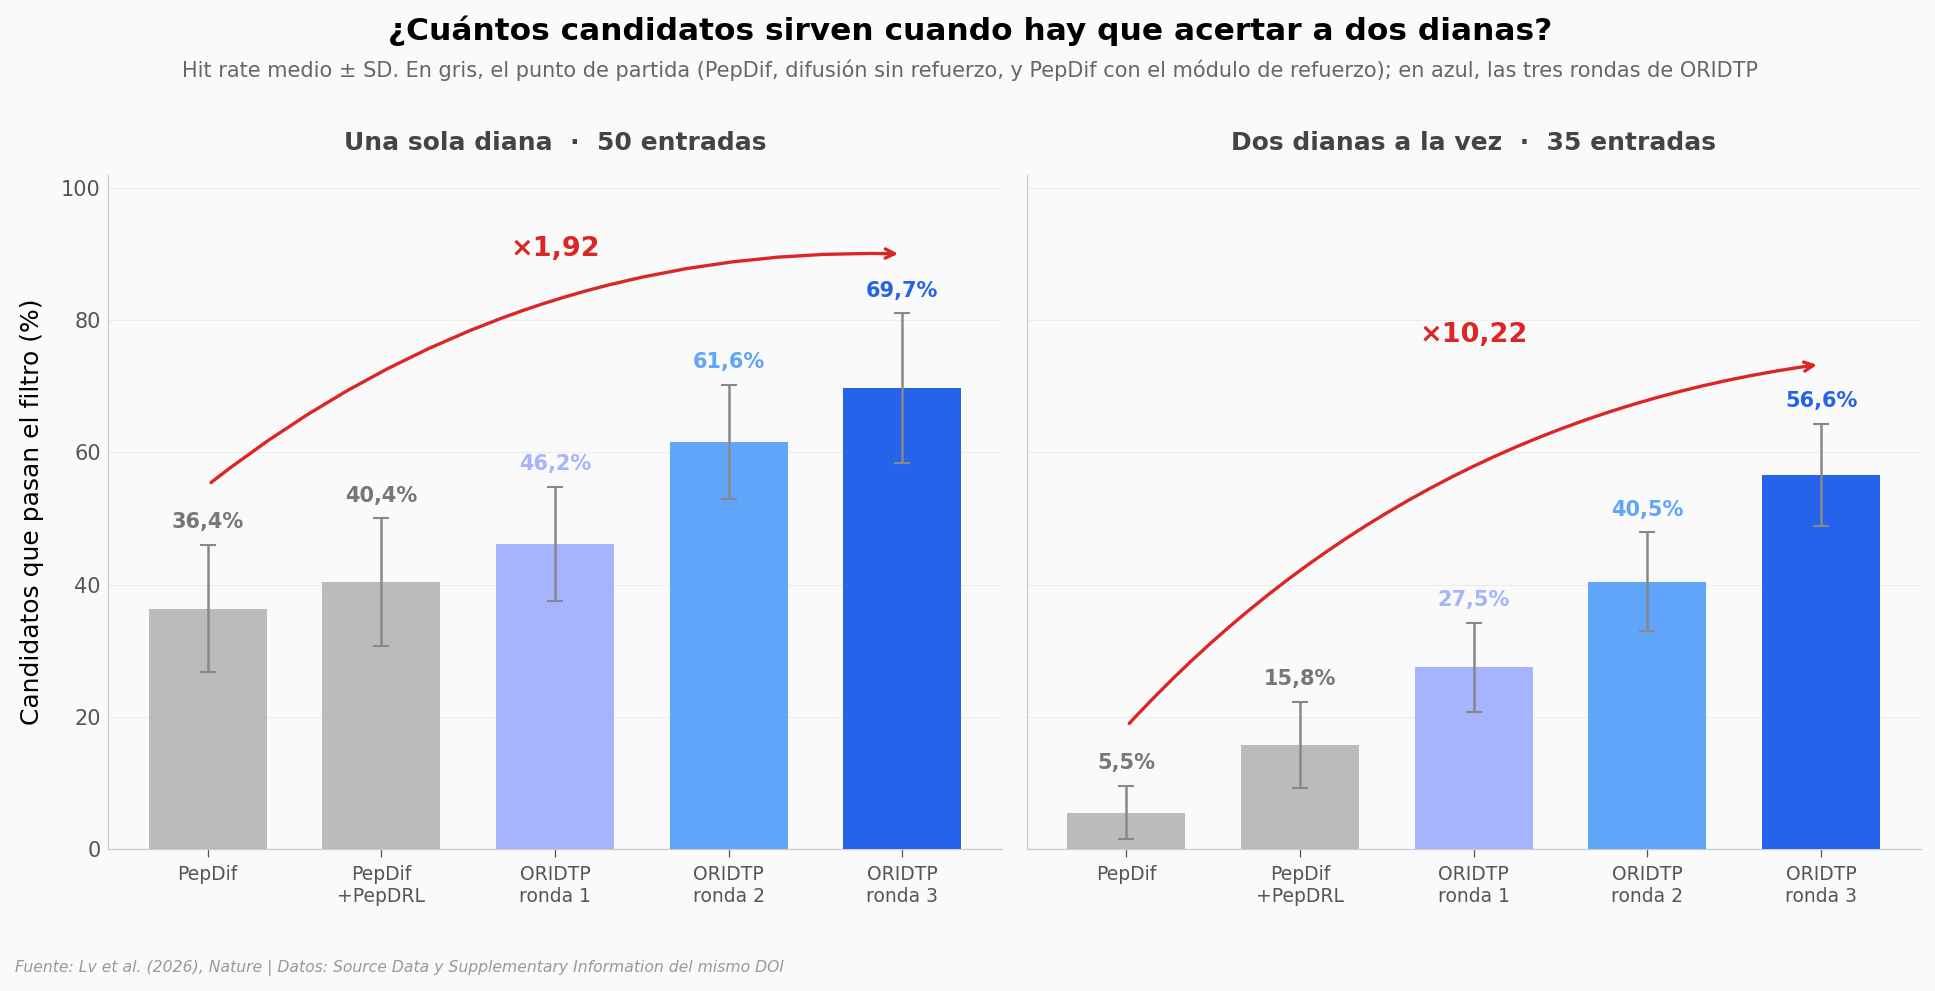

Una sola diana         (50 entradas): 36,4% → 69,7%  = ×1,92  (+33,3 puntos porcentuales)
Dos dianas a la vez    (35 entradas): 5,5% → 56,6%  = ×10,22  (+51,1 puntos porcentuales)
single-target: otras métricas (base → ORIDTP): Diversity 0,781→0,772 · Affinity / 10 0,520→0,727 · pLDDT / 100 0,800→0,892 · ipTM 0,723→0,821 · Non-Coil 0,428→0,521
dual-target: otras métricas (base → ORIDTP): Diversity 0,758→0,702 · Affinity / 10 0,420→0,690 · pLDDT / 100 0,680→0,810 · ipTM 0,651→0,782 · Non-Coil 0,412→0,508


In [2]:
ORDEN = ['PepDif', 'PepDif+PepDRL', 'ORIDTP (iter1)', 'ORIDTP (iter2)', 'ORIDTP (iter3)']
ETIQ = ['PepDif', 'PepDif\n+PepDRL', 'ORIDTP\nronda 1', 'ORIDTP\nronda 2', 'ORIDTP\nronda 3']
COLS = [COLOR_GRIS, COLOR_GRIS, '#A5B4FC', '#60A5FA', COLOR_DATOS]
PANELES = [('single-target', 'Una sola diana', 50), ('dual-target', 'Dos dianas a la vez', 35)]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
for ax, (bench, titulo, n_ent) in zip(axes, PANELES):
    s = hit[hit.benchmark == bench].set_index('metodo').loc[ORDEN]
    y = s.hit_rate_medio.values * 100
    e = s.hit_rate_sd.values * 100
    ax.bar(range(5), y, yerr=e, color=COLS, width=0.68, capsize=4,
           error_kw=dict(ecolor='#888888', lw=1.2), zorder=4)
    for i, (v, err) in enumerate(zip(y, e)):
        ax.text(i, v + err + 2.5, es(f'{v:.1f}%'), ha='center', fontsize=10,
                fontweight='bold', color=COLS[i] if i > 1 else '#777777')
    ax.annotate('', xy=(4, y[4] + e[4] + 9), xytext=(0, y[0] + e[0] + 9),
                arrowprops=dict(arrowstyle='->', color=COLOR_ALERTA, lw=1.6,
                                connectionstyle='arc3,rad=-0.18'))
    ax.text(2, y.max() + 20, es(f'×{y[4] / y[0]:.2f}'), ha='center', fontsize=13,
            fontweight='bold', color=COLOR_ALERTA)
    ax.set_xticks(range(5))
    ax.set_xticklabels(ETIQ, fontsize=9)
    ax.set_title(f'{titulo}  ·  {n_ent} entradas', fontsize=12, pad=12, color='#444444')
    ax.set_ylim(0, 102)
    ax.yaxis.set_major_formatter(COMA)
axes[0].set_ylabel('Candidatos que pasan el filtro (%)')

fig.tight_layout()
fig.suptitle('¿Cuántos candidatos sirven cuando hay que acertar a dos dianas?',
             fontsize=15, fontweight='bold', y=1.11)
fig.text(0.5, 1.035, 'Hit rate medio ± SD. En gris, el punto de partida (PepDif, difusión sin refuerzo, y PepDif con el módulo de refuerzo); '
         'en azul, las tres rondas de ORIDTP',
         ha='center', fontsize=10, color='#666666')
fig.text(0.01, -0.05, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/hit_rate_benchmark.png', dpi=200, bbox_inches='tight')
plt.show()

for bench, titulo, n_ent in PANELES:
    s = hit[hit.benchmark == bench].set_index('metodo').loc[ORDEN]
    lo, hi = s.hit_rate_medio.iloc[0] * 100, s.hit_rate_medio.iloc[-1] * 100
    pr(f'{titulo:22s} ({n_ent} entradas): {lo:.1f}% → {hi:.1f}%  = ×{hi / lo:.2f}  (+{hi - lo:.1f} puntos porcentuales)')
otras = metricas[metricas.metrica != 'Hit rate']
for bench in ['single-target', 'dual-target']:
    s = otras[otras.benchmark == bench]
    pr(f'{bench}: otras métricas (base → ORIDTP):',
       ' · '.join(f'{r.metrica} {r.pepdif_baseline:.3f}→{r.oridtp:.3f}' for r in s.itertuples()))

Hay dos saltos, y no son del mismo tamaño. Con **una sola diana** el margen de mejora era estrecho: el método de difusión de partida ya acertaba en 36,4 de cada 100 intentos y ORIDTP llega a 69,7 — un ×1,92. Con **dos dianas** el punto de partida era casi el suelo (5,5 %) y el final es 56,6 %: un ×10,22, o 51,1 puntos porcentuales.

El ×10,22 compara los dos extremos de la fila, y vale la pena ver el escalón de en medio: añadirle el módulo de refuerzo al método de difusión ya sube el acierto de 5,5 % a 15,8 %. Las tres rondas de ORIDTP no son tres versiones del programa, son tres vueltas del mismo bucle —diseñar, evaluar, reentrenar con lo aprendido— y cada vuelta añade entre 12 y 16 puntos porcentuales más.

⚠️ Dos cosas que este panel **no** dice. Primero, el *hit rate* es un filtro computacional: mide cuántos candidatos pasan el criterio de afinidad **predicha**, no cuántos funcionan en un animal. Segundo, el ×10,22 pertenece solo al régimen de dos dianas; usarlo para hablar de "diseño de péptidos" en general sería inflarlo cinco veces.

De la pantalla al banco de laboratorio. El equipo sintetizó 20 de esos péptidos —en cinco rondas sucesivas, R1 a R5— y midió en células cuánto activan cada receptor. La medida es el **EC50**: la concentración a la que se alcanza la mitad del efecto máximo. Cuanto más baja, más potente.

Y aquí entra la vara de medir interesante. La pregunta del paper no es si los péptidos de IA son potentes, sino si le ganan a lo que ya fabrica el cuerpo: el GLP-1 y el glucagón naturales. Esa línea no está tabulada en ninguna parte del paper, pero sí se puede despejar: la Suppl Table 10 da el EC50 **relativo al péptido natural** de tres péptidos y las Tables 6 y 7 dan sus EC50 absolutos, así que el producto de los dos devuelve el EC50 del natural. Los tres coinciden: **40,8 pM para el GLP-1** y **1,40 nM para el glucagón**.

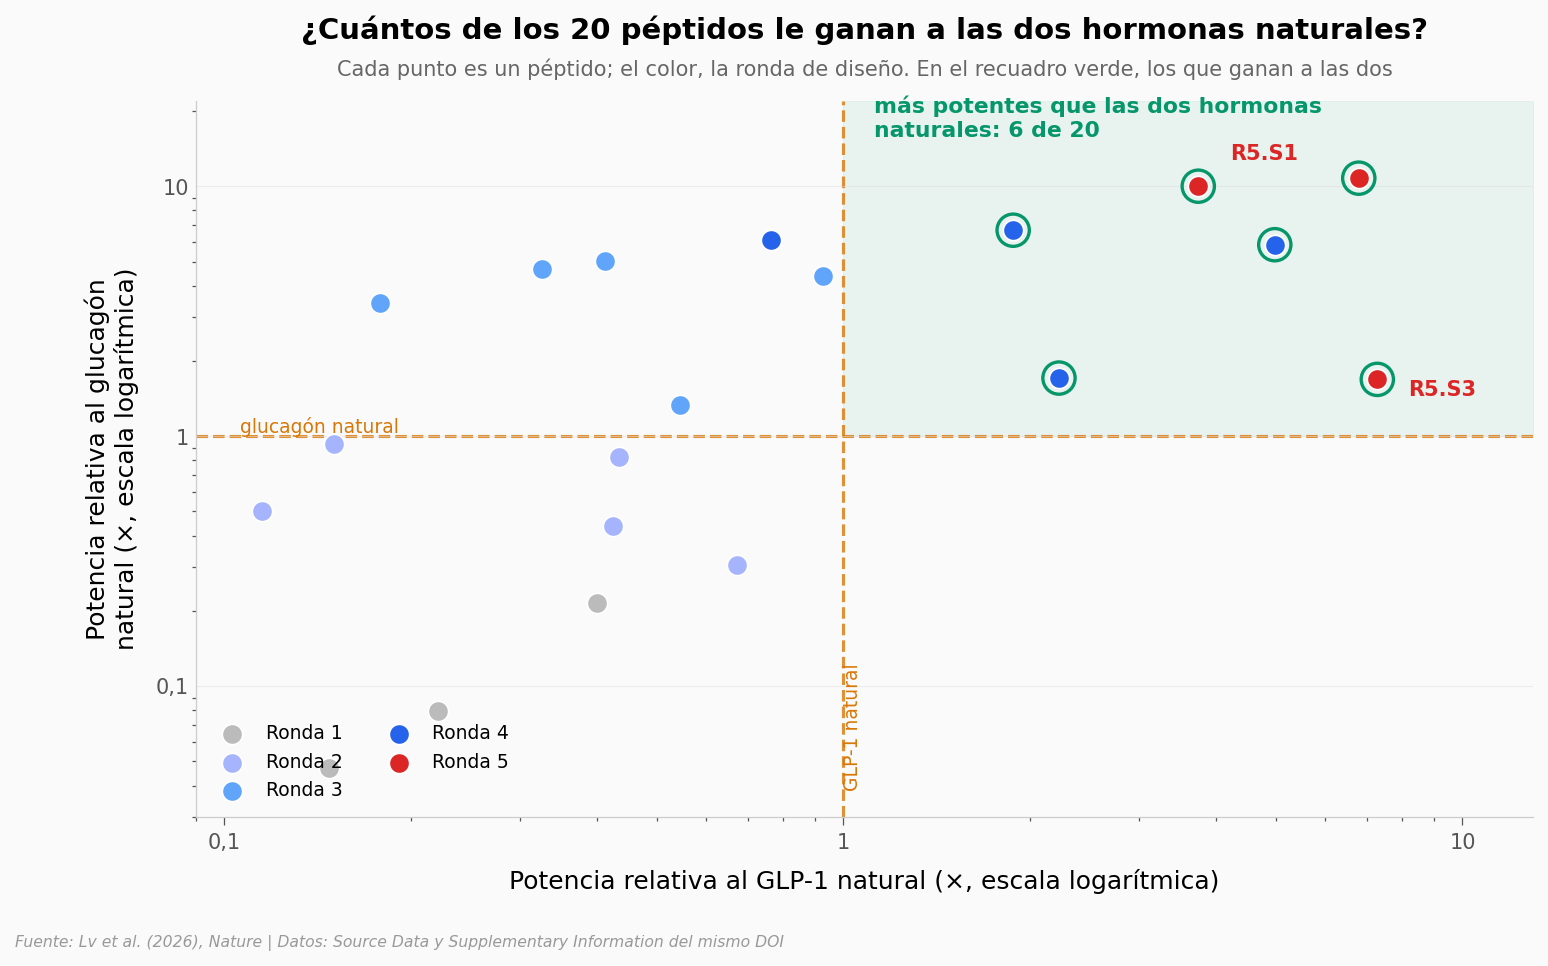

Línea base despejada con los 3 péptidos de la ronda 5 (los que publican su potencia relativa):
   GLP-1: 40,8 · 40,8 · 40,8 pM  ·  glucagón: 1,40 · 1,40 · 1,40 nM — los tres coinciden, así que la derivación se sostiene
   ⚠️ para los otros 17 péptidos, la potencia relativa es nuestra: EC50 absoluto ÷ esa línea base
Superan al natural en AMBOS receptores: 6 de 20 — R4.S2, R4.S3, R4.S4, R5.S1, R5.S2, R5.S3
   solo en GLP-1R: 6 de 20  · solo en GCGR: 12 de 20
   mediana GLP-1R: ×0,49  (IQR ×0,30 a ×1,97) — distribución muy dispersa
   mediana GCGR : ×1,70  (IQR ×0,48 a ×5,21) — distribución muy dispersa
EC50 más bajo en GLP-1R: 5,6 pM (GA-Dual.R5.S3) · en GCGR: 0,13 nM (GA-Dual.R5.S1)
Ganancia desde la referencia de la ronda 1 (GA-Dual.R1.S2): ×49,4 en GLP-1R y ×223,4 en GCGR (folds de la Fig. 2b)
   recalculado desde los EC50 redondeados de las Suppl Tables: ×49,4 y ×230,0 — el GCGR cambia por el redondeo de 0,13 nM


In [3]:
COLOR_RONDA = {'Round1': COLOR_GRIS, 'Round2': '#A5B4FC', 'Round3': '#60A5FA',
               'Round4': COLOR_DATOS, 'Round5': COLOR_ALERTA}
NOMBRE_RONDA = {'Round1': 'Ronda 1', 'Round2': 'Ronda 2', 'Round3': 'Ronda 3',
                'Round4': 'Ronda 4', 'Round5': 'Ronda 5'}

# Línea base: la Suppl Table 10 publica la potencia relativa al péptido natural de los 3 péptidos
# de la ronda 5. Con su EC50 absoluto (Suppl Tables 6 y 7), el producto devuelve el EC50 del natural.
r5 = ec50[ec50.ronda == 'Round5']
nativo_glp1r = (r5.ec50_glp1r_pm * r5.ec50_rel_glp1r_vs_nativo).round(1)
nativo_gcgr = (r5.ec50_gcgr_nm * r5.ec50_rel_gcgr_vs_nativo).round(2)
gana_ambos = ec50[(ec50.ec50_rel_glp1r_vs_nativo > 1) & (ec50.ec50_rel_gcgr_vs_nativo > 1)]
XLIM, YLIM = (0.09, 13.0), (0.03, 22.0)

fig, ax = plt.subplots(figsize=(11.5, 6.2))
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(*XLIM)
ax.set_ylim(*YLIM)
ax.fill_between([1, XLIM[1]], 1, YLIM[1], color=COLOR_SEC, alpha=0.07, zorder=0)
ax.axvline(1, color=COLOR_REFERENCIA, lw=1.5, ls='--', alpha=0.8, zorder=1)
ax.axhline(1, color=COLOR_REFERENCIA, lw=1.5, ls='--', alpha=0.8, zorder=1)
for ronda, g in ec50.groupby('ronda'):
    ax.scatter(g.ec50_rel_glp1r_vs_nativo, g.ec50_rel_gcgr_vs_nativo, s=95, zorder=5,
               color=COLOR_RONDA[ronda], edgecolors='white', linewidths=0.8,
               label=NOMBRE_RONDA[ronda])
ax.scatter(gana_ambos.ec50_rel_glp1r_vs_nativo, gana_ambos.ec50_rel_gcgr_vs_nativo,
           s=240, facecolors='none', edgecolors=COLOR_SEC, linewidths=1.6, zorder=4)
for p, dx, dy in [('GA-Dual.R5.S3', 1.12, 0.86), ('GA-Dual.R5.S1', 0.62, 1.18)]:
    r = ec50[ec50.peptido == p].iloc[0]
    ax.annotate(p.replace('GA-Dual.', ''), xy=(r.ec50_rel_glp1r_vs_nativo, r.ec50_rel_gcgr_vs_nativo),
                xytext=(r.ec50_rel_glp1r_vs_nativo * dx, r.ec50_rel_gcgr_vs_nativo * dy),
                fontsize=10, fontweight='bold', color=COLOR_ALERTA)
ax.text(1.12, YLIM[1] * 0.72, f'más potentes que las dos hormonas\nnaturales: {len(gana_ambos)} de {len(ec50)}',
        fontsize=10.5, color=COLOR_SEC, fontweight='bold')
ax.text(1.0, YLIM[0] * 1.2, ' GLP-1 natural', fontsize=9, color=COLOR_REFERENCIA,
        ha='left', va='bottom', rotation=90)
ax.text(XLIM[0] * 1.15, 1.0, ' glucagón natural', fontsize=9, color=COLOR_REFERENCIA,
        ha='left', va='bottom')
ax.set_xlabel('Potencia relativa al GLP-1 natural (×, escala logarítmica)')
ax.set_ylabel('Potencia relativa al glucagón\nnatural (×, escala logarítmica)')
ax.set_title('¿Cuántos de los 20 péptidos le ganan a las dos hormonas naturales?',
             fontsize=14, fontweight='bold', pad=30)
ax.text(0.5, 1.035, 'Cada punto es un péptido; el color, la ronda de diseño. En el recuadro verde, los que ganan a las dos',
        transform=ax.transAxes, fontsize=10, color='#666666', ha='center')
ax.xaxis.set_major_formatter(COMA)
ax.yaxis.set_major_formatter(COMA)
ax.legend(fontsize=9, loc='lower left', ncol=2)
fig.text(0.02, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/potencia_relativa_nativo.png', dpi=200, bbox_inches='tight')
plt.show()

pr('Línea base despejada con los 3 péptidos de la ronda 5 (los que publican su potencia relativa):')
pr('   GLP-1:', ' · '.join(f'{v:.1f}' for v in nativo_glp1r), 'pM  ·  glucagón:',
   ' · '.join(f'{v:.2f}' for v in nativo_gcgr), 'nM — los tres coinciden, así que la derivación se sostiene')
pr('   ⚠️ para los otros 17 péptidos, la potencia relativa es nuestra: EC50 absoluto ÷ esa línea base')
pr('Superan al natural en AMBOS receptores:', len(gana_ambos), 'de', len(ec50), '—',
   ', '.join(gana_ambos.peptido.str.replace('GA-Dual.', '', regex=False)))
pr('   solo en GLP-1R:', int((ec50.ec50_rel_glp1r_vs_nativo > 1).sum()), 'de', len(ec50),
   ' · solo en GCGR:', int((ec50.ec50_rel_gcgr_vs_nativo > 1).sum()), 'de', len(ec50))
for col, nombre in [('ec50_rel_glp1r_vs_nativo', 'GLP-1R'), ('ec50_rel_gcgr_vs_nativo', 'GCGR ')]:
    q1, q3 = np.percentile(ec50[col], [25, 75])
    pr(f'   mediana {nombre}: ×{ec50[col].median():.2f}  (IQR ×{q1:.2f} a ×{q3:.2f}) — distribución muy dispersa')
mejor_g = ec50.loc[ec50.ec50_glp1r_pm.idxmin()]
mejor_c = ec50.loc[ec50.ec50_gcgr_nm.idxmin()]
pr(f'EC50 más bajo en GLP-1R: {mejor_g.ec50_glp1r_pm} pM ({mejor_g.peptido}) · en GCGR: {mejor_c.ec50_gcgr_nm} nM ({mejor_c.peptido})')
pr('Ganancia desde la referencia de la ronda 1 (GA-Dual.R1.S2):',
   f'×{folds_fig.glp1r_fold.max():.1f} en GLP-1R y ×{folds_fig.gcgr_fold.max():.1f} en GCGR (folds de la Fig. 2b)')
pr('   recalculado desde los EC50 redondeados de las Suppl Tables:',
   f'×{ec50.fold_glp1r_vs_ref.max():.1f} y ×{ec50.fold_gcgr_vs_ref.max():.1f} — el GCGR cambia por el redondeo de 0,13 nM')

Seis de los 20 caen en el cuadrante verde: son más potentes que el GLP-1 **y** que el glucagón. Aparecen todos en las rondas 4 y 5, las últimas del bucle.

Pero mira dónde está el centro de la nube. La mediana de los 20 es ×0,49 frente al GLP-1 (IQR ×0,30 a ×1,97): **la mayoría de los péptidos diseñados no le gana al GLP-1 natural**. El titular vive en la cola de la distribución, no en el promedio — y eso es lo normal en un proceso de diseño iterativo, donde lo que importa es el mejor candidato, no la media del lote. Conviene decirlo igual.

El elegido para los experimentos en animales fue **R5.S3**: ×7,29 frente al GLP-1 y ×1,69 frente al glucagón. Con él, el equipo se fue a los ratones obesos.

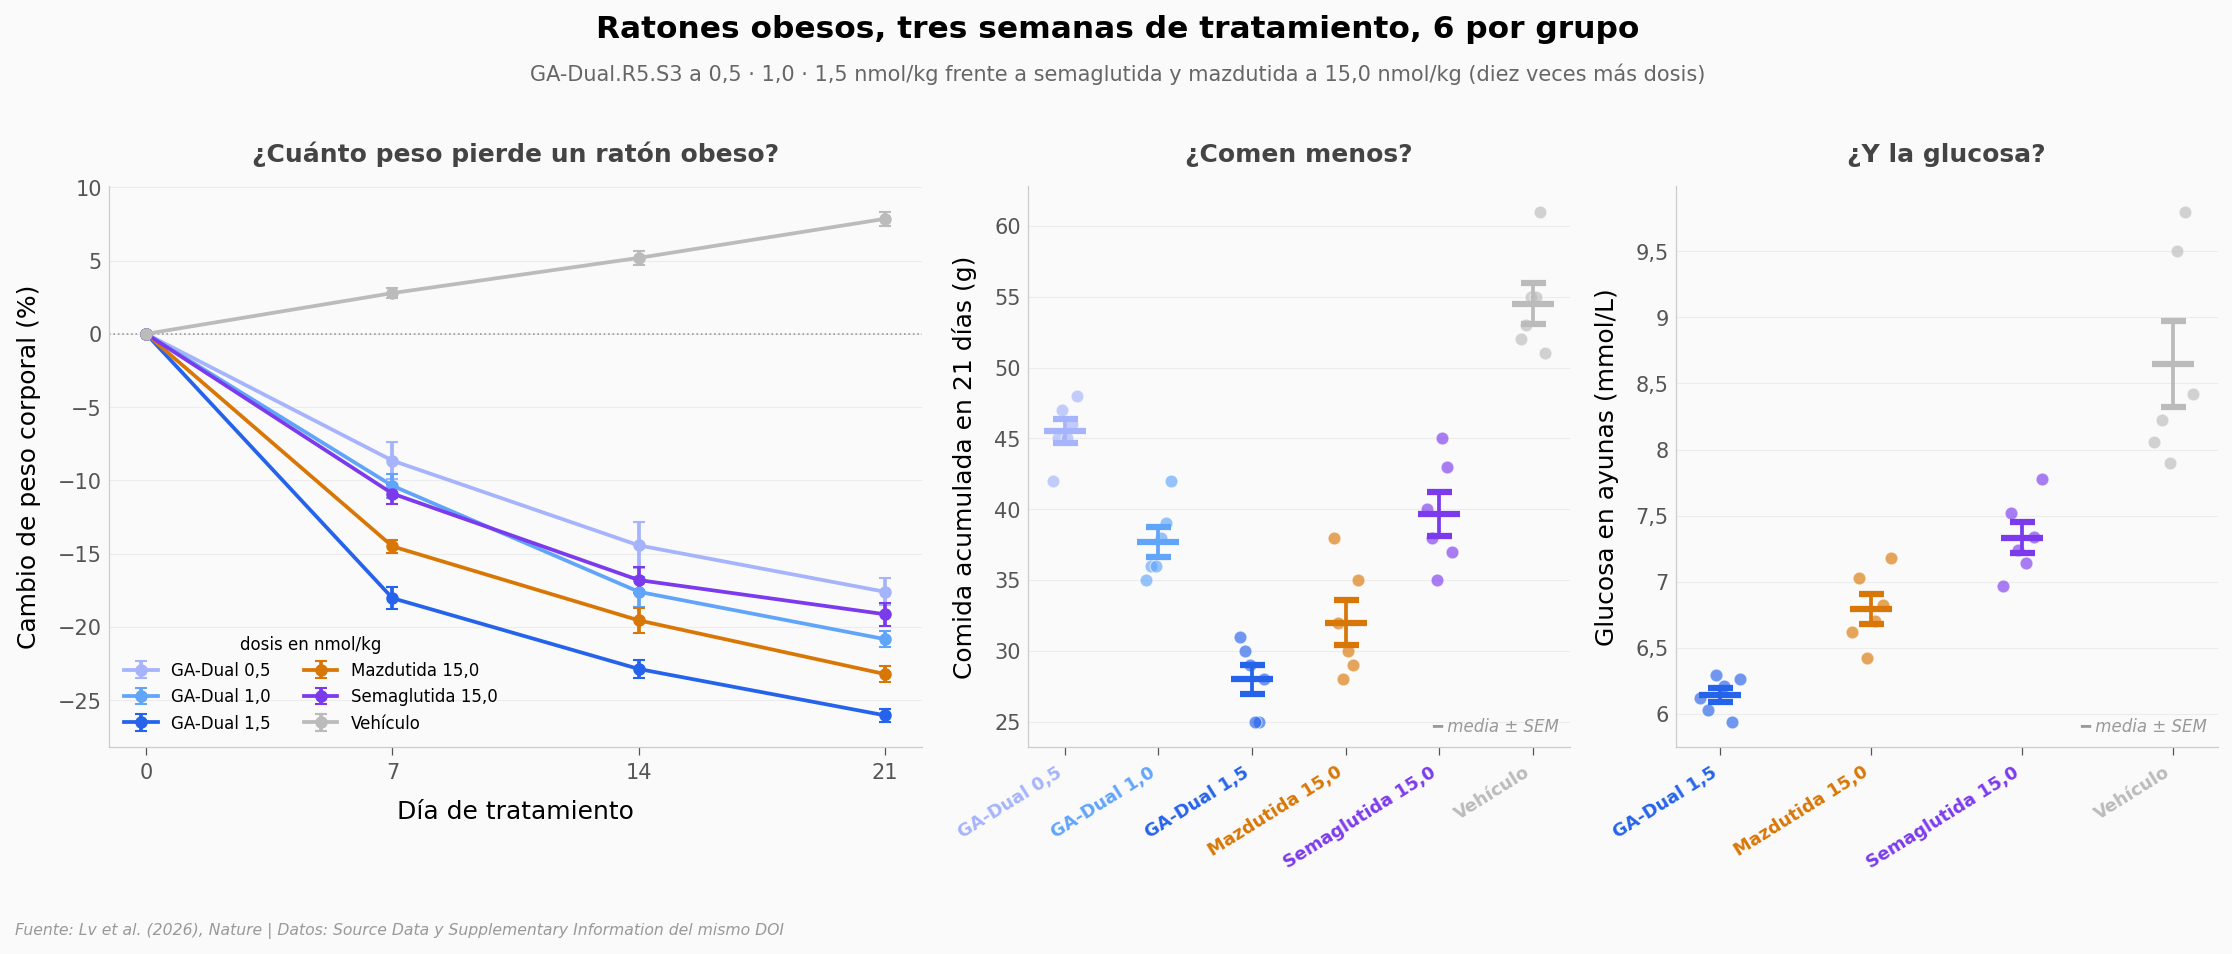

── Peso corporal, día 21 (%, n=6 por grupo)
   GA-Dual 0,5         −17,60 % ± 2,25 (SD) · mediana  −16,70 %
   GA-Dual 1,0         −20,83 % ± 1,31 (SD) · mediana  −21,05 %
   GA-Dual 1,5         −26,03 % ± 1,05 (SD) · mediana  −26,00 %
   Mazdutida 15,0      −23,22 % ± 1,39 (SD) · mediana  −23,55 %
   Semaglutida 15,0    −19,13 % ± 1,93 (SD) · mediana  −19,20 %
   Vehículo              7,85 % ± 1,18 (SD) · mediana    8,00 %
── GA-Dual.R5.S3 (1,5 nmol/kg) frente a los demás (diferencias en puntos porcentuales, no en %)
   vs Vehículo           −33,88 pp · d de Cohen −30,34 · Mann-Whitney p=0,0022
   vs Semaglutida 15,0    −6,90 pp · d de Cohen  −4,45 · Mann-Whitney p=0,0022
   vs Mazdutida 15,0      −2,82 pp · d de Cohen  −2,29 · Mann-Whitney p=0,0043
   (con 6 contra 6 el p más bajo que puede dar Mann-Whitney es 0,0022: la p no distingue entre estas tres comparaciones, la d sí)
── Comida acumulada día 21 (g) y glucosa en ayunas (mmol/L)
   GA-Dual 0,5         45,5 g ± 2,1
   GA-Dual 1,

In [4]:
GRUPOS_DIO = ['GA-Dual.R5.S3 (0.5 nmol/kg)', 'GA-Dual.R5.S3 (1.0 nmol/kg)', 'GA-Dual.R5.S3 (1.5 nmol/kg)',
              'Mazdutide (15.0 nmol/kg)', 'Semaglutide (15.0 nmol/kg)', 'Vehicle']

def strip_grupos(ax, df, col, grupos, ylabel, titulo):
    np.random.seed(42)
    pos = np.arange(len(grupos), dtype=float)
    for i, g in enumerate(grupos):
        v = df[df.iloc[:, 0] == g][col].values
        x = np.linspace(pos[i] - 0.13, pos[i] + 0.13, len(v))
        np.random.shuffle(x)
        ax.scatter(x, v, color=COLOR.get(g, COLOR_DATOS), s=38, alpha=0.65,
                   edgecolors='white', linewidths=0.5, zorder=5)
        ax.errorbar(pos[i], v.mean(), yerr=v.std(ddof=1) / np.sqrt(len(v)), fmt='_',
                    color=COLOR.get(g, COLOR_DATOS), markersize=20, markeredgewidth=3,
                    capsize=6, capthick=1.5, zorder=6)
    ax.set_xticks(pos)
    ax.set_xticklabels([CORTO.get(g, g).replace('\n', ' ') for g in grupos], fontsize=8.5,
                       fontweight='bold', rotation=32, ha='right')
    for tick, g in zip(ax.get_xticklabels(), grupos):
        tick.set_color(COLOR.get(g, COLOR_DATOS))
    ax.set_ylabel(ylabel)
    ax.set_title(titulo, fontsize=12, pad=12, color='#444444')
    ax.yaxis.set_major_formatter(COMA)
    ax.text(0.98, 0.02, '━ media ± SEM', transform=ax.transAxes, fontsize=8,
            color='#999999', ha='right', va='bottom', style='italic')

fig, axes = plt.subplots(1, 3, figsize=(15, 5.2), gridspec_kw=dict(width_ratios=[1.5, 1, 1]))

ax = axes[0]
for g in GRUPOS_DIO:
    s = peso[peso.tratamiento == g].groupby('dia').cambio_peso_pct
    m, sem = s.mean(), s.std(ddof=1) / np.sqrt(s.count())
    ax.errorbar(m.index, m.values, yerr=sem.values, color=COLOR[g], marker='o',
                markersize=5, capsize=3, lw=1.8, label=CORTO[g].replace('\n', ' '))
ax.axhline(0, color='#999999', lw=0.8, ls=':')
ax.set_xticks(sorted(peso.dia.unique()))
ax.set_xlabel('Día de tratamiento')
ax.set_ylabel('Cambio de peso corporal (%)')
ax.set_title('¿Cuánto peso pierde un ratón obeso?', fontsize=12, pad=12, color='#444444')
ax.legend(fontsize=8, loc='lower left', ncol=2, title='dosis en nmol/kg', title_fontsize=8)
ax.yaxis.set_major_formatter(COMA)

ing_f = ingesta[ingesta.dia == DIA_FINAL_DIO]
strip_grupos(axes[1], ing_f, 'ingesta_acumulada_g', GRUPOS_DIO,
             'Comida acumulada en 21 días (g)', '¿Comen menos?')
strip_grupos(axes[2], glucosa, 'glucosa_ayunas_mmol_l',
             [g for g in GRUPOS_DIO if g in set(glucosa.tratamiento)],
             'Glucosa en ayunas (mmol/L)', '¿Y la glucosa?')

fig.tight_layout()
fig.suptitle('Ratones obesos, tres semanas de tratamiento, 6 por grupo',
             fontsize=15, fontweight='bold', y=1.13)
fig.text(0.5, 1.045, 'GA-Dual.R5.S3 a 0,5 · 1,0 · 1,5 nmol/kg frente a semaglutida y mazdutida a 15,0 nmol/kg (diez veces más dosis)',
         ha='center', fontsize=10, color='#666666')
fig.text(0.01, -0.05, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/ratones_obesos.png', dpi=200, bbox_inches='tight')
plt.show()

p_d21 = peso[peso.dia == DIA_FINAL_DIO]
pr(f'── Peso corporal, día {DIA_FINAL_DIO} (%, n=6 por grupo)')
for g in GRUPOS_DIO:
    v = p_d21[p_d21.tratamiento == g].cambio_peso_pct
    pr(f'   {CORTO[g].replace(chr(10), " "):18s} {v.mean():7.2f} % ± {v.std(ddof=1):.2f} (SD) · mediana {v.median():7.2f} %')
ga = p_d21[p_d21.tratamiento == GA].cambio_peso_pct
pr(f'── {GA} frente a los demás (diferencias en puntos porcentuales, no en %)')
for g in ['Vehicle', 'Semaglutide (15.0 nmol/kg)', 'Mazdutide (15.0 nmol/kg)']:
    v = p_d21[p_d21.tratamiento == g].cambio_peso_pct
    pr(f'   vs {CORTO[g].replace(chr(10), " "):18s} {ga.mean() - v.mean():+6.2f} pp · d de Cohen {cohen_d(ga, v):6.2f} · Mann-Whitney p={mw(ga, v):.4f}')
pr('   (con 6 contra 6 el p más bajo que puede dar Mann-Whitney es 0,0022: la p no distingue entre estas tres comparaciones, la d sí)')
pr(f'── Comida acumulada día {DIA_FINAL_DIO} (g) y glucosa en ayunas (mmol/L)')
for g in GRUPOS_DIO:
    v = ing_f[ing_f.tratamiento == g].ingesta_acumulada_g
    gl = glucosa[glucosa.tratamiento == g].glucosa_ayunas_mmol_l
    extra = f' · glucosa {gl.mean():.2f} ± {gl.std(ddof=1):.2f}' if len(gl) else ''
    pr(f'   {CORTO[g].replace(chr(10), " "):18s} {v.mean():5.1f} g ± {v.std(ddof=1):.1f}{extra}')
grupos_gl = [v.values for _, v in glucosa.groupby('tratamiento').glucosa_ayunas_mmol_l]
f_stat, p_anova = stats.f_oneway(*grupos_gl)
pr(f'   ANOVA de una vía sobre la glucosa: F={f_stat:.1f}, p={p_anova:.2e} (4 grupos, n=6)')
# La glucosa en ayunas y el HOMA-IR solo se midieron a 1,5 nmol/kg: ese grupo es fijo aquí
GA_FIJO = 'GA-Dual.R5.S3 (1.5 nmol/kg)'
gl_ga = glucosa[glucosa.tratamiento == GA_FIJO].glucosa_ayunas_mmol_l
gl_sema = glucosa[glucosa.tratamiento == 'Semaglutide (15.0 nmol/kg)'].glucosa_ayunas_mmol_l
pr(f'   GA-Dual 1,5 nmol/kg vs semaglutida 15,0: {gl_ga.mean() - gl_sema.mean():+.2f} mmol/L · d={cohen_d(gl_ga, gl_sema):.2f} · p={mw(gl_ga, gl_sema):.4f}')

Un atajo tentador para bajar de peso es dar náusea: si la comida repugna, el animal come menos. Los agonistas de GLP-1 arrastran ese efecto en la clínica, y el paper afirma que su péptido baja el peso **sin** provocar náusea ni aversión. Esa clase de afirmación —"no pasa nada"— es la más fácil de colar y la más difícil de sostener, porque no encontrar un efecto puede significar simplemente que el experimento no tiene la sensibilidad para verlo.

La defensa está en los controles positivos. En el test de aversión al sabor, un grupo recibe **cloruro de litio**, que da malestar de libro. En el test de *pica* —la manía de comer tierra o arcilla cuando algo revuelve el estómago— el control positivo es **cisplatino**, un quimioterápico que provoca náusea. Si esos dos mueven la aguja y el péptido no, la ausencia de efecto significa algo.

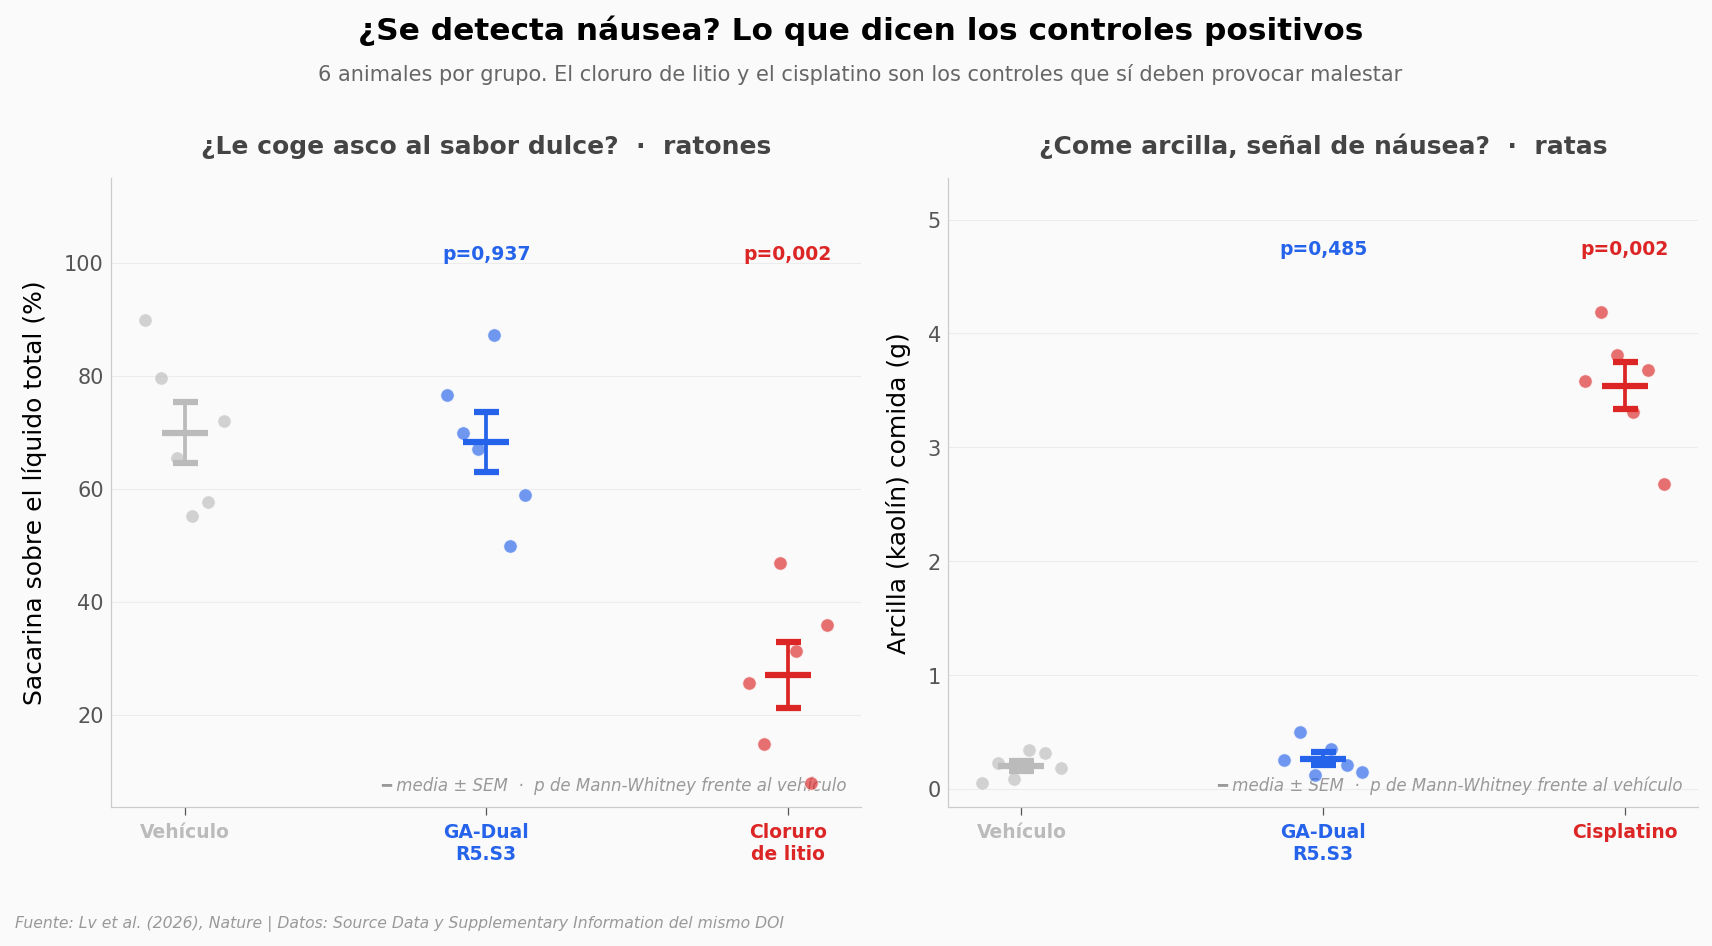

── Sacarina sobre el líquido total (%) (n=6 por grupo)
   Vehículo            69,90 % ± 13,26 (SD) · mediana 68,65
   GA-Dual R5.S3       68,25 % ± 13,11 (SD) · mediana 68,50 · vs vehículo −1,65 pp · d=−0,13 · p=0,9372
   Cloruro de litio    26,98 % ± 14,19 (SD) · mediana 28,35 · vs vehículo −42,92 pp · d=−3,12 · p=0,0022
── Arcilla (kaolín) comida (g) (n=6 por grupo)
   Vehículo             0,20 g ± 0,12 (SD) · mediana 0,21
   GA-Dual R5.S3        0,26 g ± 0,14 (SD) · mediana 0,23 · vs vehículo +0,06 g · d= 0,49 · p=0,4848
   Cisplatino           3,54 g ± 0,51 (SD) · mediana 3,63 · vs vehículo +3,34 g · d= 9,01 · p=0,0022


In [5]:
PANELES_AV = [
    (sacarina, 'grupo', 'sacarina_pct', ['Vehicle', 'GA-Dual.R5.S3', 'LiCl'],
     ['Vehículo', 'GA-Dual\nR5.S3', 'Cloruro\nde litio'], 'Sacarina sobre el líquido total (%)',
     '¿Le coge asco al sabor dulce?  ·  ratones'),
    (kaolin, 'grupo', 'kaolin_g', ['Vehicle', 'GA-Dual.R5.S3', 'Cisplatin'],
     ['Vehículo', 'GA-Dual\nR5.S3', 'Cisplatino'], 'Arcilla (kaolín) comida (g)',
     '¿Come arcilla, señal de náusea?  ·  ratas'),
]
COL_AV = [COLOR_GRIS, COLOR_DATOS, COLOR_ALERTA]

fig, axes = plt.subplots(1, 2, figsize=(11.5, 5.2))
np.random.seed(42)
for ax, (df, gcol, vcol, grupos, etiq, ylabel, titulo) in zip(axes, PANELES_AV):
    pos = np.arange(len(grupos), dtype=float)
    for i, g in enumerate(grupos):
        v = df[df[gcol] == g][vcol].values
        x = np.linspace(pos[i] - 0.13, pos[i] + 0.13, len(v))
        np.random.shuffle(x)
        ax.scatter(x, v, color=COL_AV[i], s=42, alpha=0.65, edgecolors='white',
                   linewidths=0.5, zorder=5)
        ax.errorbar(pos[i], v.mean(), yerr=v.std(ddof=1) / np.sqrt(len(v)), fmt='_',
                    color=COL_AV[i], markersize=22, markeredgewidth=3, capsize=6,
                    capthick=1.5, zorder=6)
    ref = df[df[gcol] == grupos[0]][vcol].values
    techo = df[vcol].max()
    ax.set_ylim(top=techo * 1.28)
    for i, g in enumerate(grupos[1:], start=1):
        v = df[df[gcol] == g][vcol].values
        ax.text(pos[i], techo * 1.12, es(f'p={mw(v, ref):.3f}'), ha='center',
                fontsize=9, color=COL_AV[i], fontweight='bold')
    ax.set_xticks(pos)
    ax.set_xticklabels(etiq, fontsize=9, fontweight='bold')
    for tick, c in zip(ax.get_xticklabels(), COL_AV):
        tick.set_color(c)
    ax.set_ylabel(ylabel)
    ax.set_title(titulo, fontsize=12, pad=12, color='#444444')
    ax.yaxis.set_major_formatter(COMA)
    ax.text(0.98, 0.02, '━ media ± SEM  ·  p de Mann-Whitney frente al vehículo',
            transform=ax.transAxes, fontsize=8, color='#999999', ha='right', va='bottom', style='italic')

fig.tight_layout()
fig.suptitle('¿Se detecta náusea? Lo que dicen los controles positivos',
             fontsize=15, fontweight='bold', y=1.12)
fig.text(0.5, 1.035, '6 animales por grupo. El cloruro de litio y el cisplatino son los controles que sí deben provocar malestar',
         ha='center', fontsize=10, color='#666666')
fig.text(0.01, -0.05, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/nausea_aversion.png', dpi=200, bbox_inches='tight')
plt.show()

for df, gcol, vcol, grupos, etiq, ylabel, titulo in PANELES_AV:
    es_pct = vcol.endswith('pct')
    unidad = '%' if es_pct else 'g'
    unidad_dif = 'pp' if es_pct else 'g'   # en una escala en %, la diferencia va en puntos porcentuales
    pr(f'── {ylabel} (n=6 por grupo)')
    ref = df[df[gcol] == grupos[0]][vcol]
    for g, nombre in zip(grupos, etiq):
        v = df[df[gcol] == g][vcol]
        linea = f'   {nombre.replace(chr(10), " "):18s} {v.mean():6.2f} {unidad} ± {v.std(ddof=1):.2f} (SD) · mediana {v.median():.2f}'
        if g != grupos[0]:
            linea += f' · vs vehículo {v.mean() - ref.mean():+.2f} {unidad_dif} · d={cohen_d(v, ref):5.2f} · p={mw(v, ref):.4f}'
        pr(linea)

Hasta aquí, un problema: dos receptores de la misma familia, que responden a hormonas parecidas. La prueba de fuego de una plataforma es otra cosa — ¿sirve para dos dianas que no se parecen en nada?

El equipo le pidió a ORIDTP péptidos contra **PD-1 y CTLA-4** sin reentrenarlo para esa tarea. Son dos frenos del sistema inmune con estructuras y mecanismos distintos, y hoy se bloquean con anticuerpos (nivolumab, ipilimumab) que cuestan una fortuna y pesan cien veces más que un péptido. De los 15 péptidos diseñados, el paper reporta que 8 bloquearon ambas interacciones y 3 llegaron a los ratones. Esos tres son los que podemos abrir: el Source Data trae sus curvas de inhibición en placa y el crecimiento del tumor animal por animal.

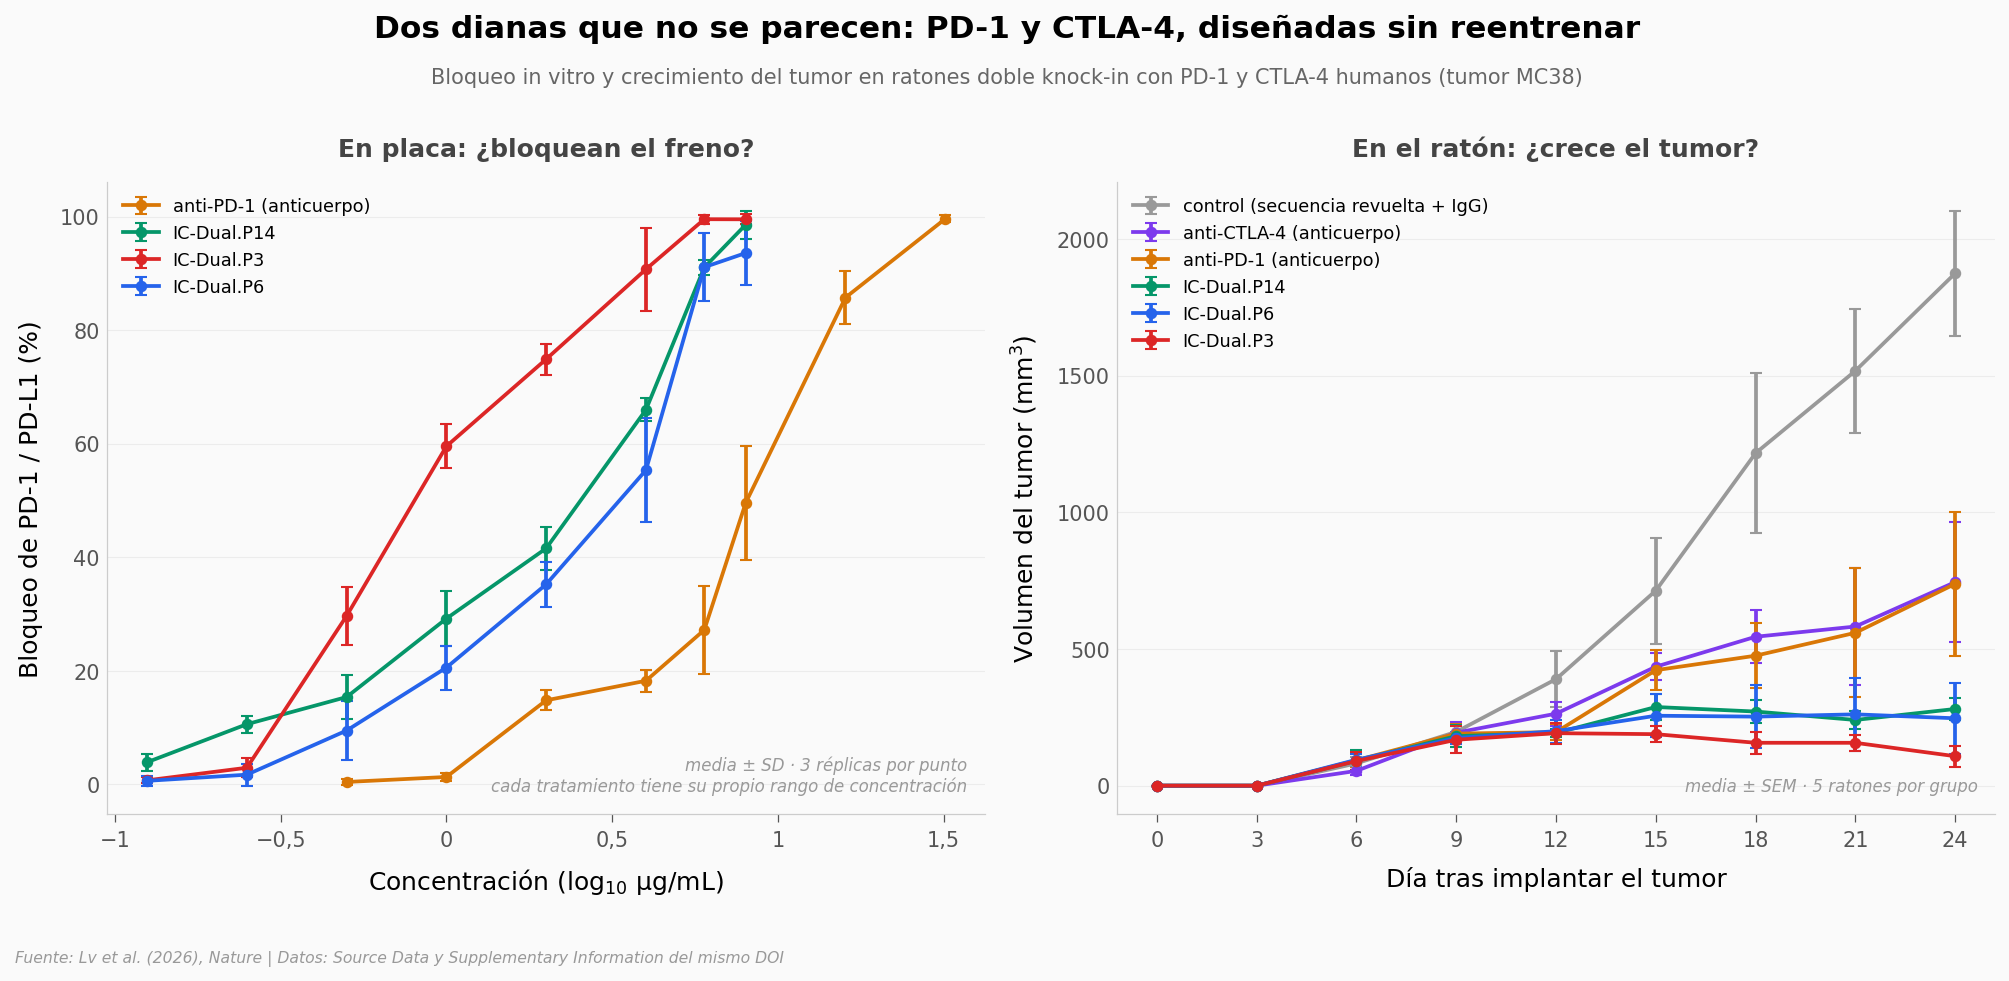

── Bloqueo máximo in vitro, cada tratamiento en su concentración más alta (n=3)
   CTLA-4/CD80  anti-CTLA-4 (anticuerpo)    99,1 % ± 1,0 a 6,0 µg/mL
   CTLA-4/CD80  IC-Dual.P14                 98,7 % ± 1,2 a 3,0 µg/mL
   CTLA-4/CD80  IC-Dual.P3                 100,0 % ± 0,0 a 4,0 µg/mL
   CTLA-4/CD80  IC-Dual.P6                  99,9 % ± 0,1 a 6,0 µg/mL
   PD-1/PD-L1   anti-PD-1 (anticuerpo)      99,6 % ± 0,6 a 32,0 µg/mL
   PD-1/PD-L1   IC-Dual.P14                 98,6 % ± 2,5 a 8,0 µg/mL
   PD-1/PD-L1   IC-Dual.P3                  99,5 % ± 0,9 a 8,0 µg/mL
   PD-1/PD-L1   IC-Dual.P6                  93,6 % ± 5,6 a 8,0 µg/mL
── Volumen del tumor el día 24 (mm³, n=5 por grupo)
   control (secuencia revuelta + IgG)   1.874,7 ±   514,7 (SD) · mediana   1.780,6
   anti-CTLA-4 (anticuerpo)               744,9 ±   491,1 (SD) · mediana     590,6 · −60,3 % vs control · d=−2,25 · p=0,0159
   anti-PD-1 (anticuerpo)                 738,4 ±   591,4 (SD) · mediana     549,2 · −60,6 % vs control · d

In [6]:
COLOR_IC = {'IC-Dual.P3': COLOR_ALERTA, 'IC-Dual.P6': COLOR_DATOS, 'IC-Dual.P14': COLOR_SEC,
            'Anti-PD-1 mAb': COLOR_REFERENCIA, 'Anti-CTLA-4 mAb': COLOR_VIOLETA,
            'Anti PD-1': COLOR_REFERENCIA, 'Anti CTLA-4': COLOR_VIOLETA,
            'Scrambled control+IgG': '#999999'}
NOMBRE_TUMOR = {'IC-Dual.P3': 'IC-Dual.P3', 'IC-Dual.P6': 'IC-Dual.P6', 'IC-Dual.P14': 'IC-Dual.P14',
                'Anti PD-1': 'anti-PD-1 (anticuerpo)', 'Anti CTLA-4': 'anti-CTLA-4 (anticuerpo)',
                'Scrambled control+IgG': 'control (secuencia revuelta + IgG)'}

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.4))

ax = axes[0]
pd1 = inhib[inhib.interaccion == 'PD-1/PD-L1']
for trat, g in pd1.groupby('tratamiento'):
    s = g.groupby('log10_conc_ug_ml').inhibicion_pct
    m, sd = s.mean(), s.std(ddof=1)
    ax.errorbar(m.index, m.values, yerr=sd.values, marker='o', markersize=4.5, lw=1.8,
                capsize=3, color=COLOR_IC[trat], label=trat.replace('Anti-PD-1 mAb', 'anti-PD-1 (anticuerpo)'))
ax.set_xlabel('Concentración (log$_{10}$ µg/mL)')
ax.set_ylabel('Bloqueo de PD-1 / PD-L1 (%)')
ax.set_title('En placa: ¿bloquean el freno?', fontsize=12, pad=12, color='#444444')
ax.legend(fontsize=8.5, loc='upper left')
ax.xaxis.set_major_formatter(COMA)
ax.yaxis.set_major_formatter(COMA)
ax.text(0.98, 0.03, 'media ± SD · 3 réplicas por punto\ncada tratamiento tiene su propio rango de concentración',
        transform=ax.transAxes, fontsize=8, color='#999999', ha='right', va='bottom', style='italic')

ax = axes[1]
ORDEN_TUMOR = ['Scrambled control+IgG', 'Anti CTLA-4', 'Anti PD-1', 'IC-Dual.P14', 'IC-Dual.P6', 'IC-Dual.P3']
for g in ORDEN_TUMOR:
    s = tumor[tumor.tratamiento == g].groupby('dia').volumen_tumoral_mm3
    m, sem = s.mean(), s.std(ddof=1) / np.sqrt(s.count())
    ax.errorbar(m.index, m.values, yerr=sem.values, marker='o', markersize=4.5, lw=1.8,
                capsize=3, color=COLOR_IC[g], label=NOMBRE_TUMOR[g])
ax.set_xticks(sorted(tumor.dia.unique()))
ax.set_xlabel('Día tras implantar el tumor')
ax.set_ylabel('Volumen del tumor (mm$^3$)')
ax.set_title('En el ratón: ¿crece el tumor?', fontsize=12, pad=12, color='#444444')
ax.legend(fontsize=8.5, loc='upper left')
ax.yaxis.set_major_formatter(COMA)
ax.text(0.98, 0.03, 'media ± SEM · 5 ratones por grupo', transform=ax.transAxes,
        fontsize=8, color='#999999', ha='right', va='bottom', style='italic')

fig.tight_layout()
fig.suptitle('Dos dianas que no se parecen: PD-1 y CTLA-4, diseñadas sin reentrenar',
             fontsize=15, fontweight='bold', y=1.12)
fig.text(0.5, 1.035, 'Bloqueo in vitro y crecimiento del tumor en ratones doble knock-in con PD-1 y CTLA-4 humanos (tumor MC38)',
         ha='center', fontsize=10, color='#666666')
fig.text(0.01, -0.05, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/checkpoints_tumor.png', dpi=200, bbox_inches='tight')
plt.show()

NOMBRE_IC = {'Anti-PD-1 mAb': 'anti-PD-1 (anticuerpo)', 'Anti-CTLA-4 mAb': 'anti-CTLA-4 (anticuerpo)'}
pr('── Bloqueo máximo in vitro, cada tratamiento en su concentración más alta (n=3)')
for inter, g in inhib.groupby('interaccion'):
    for trat, h in g.groupby('tratamiento'):
        top = h[h.log10_conc_ug_ml == h.log10_conc_ug_ml.max()]
        conc = 10 ** top.log10_conc_ug_ml.iloc[0]
        pr(f'   {inter:12s} {NOMBRE_IC.get(trat, trat):26s} {top.inhibicion_pct.mean():5.1f} % ± {top.inhibicion_pct.std(ddof=1):.1f} a {conc:.1f} µg/mL')
t_fin = tumor[tumor.dia == DIA_FINAL_TUMOR]
ctrl = t_fin[t_fin.tratamiento == 'Scrambled control+IgG'].volumen_tumoral_mm3
pr(f'── Volumen del tumor el día {DIA_FINAL_TUMOR} (mm³, n=5 por grupo)')
for g in ORDEN_TUMOR:
    v = t_fin[t_fin.tratamiento == g].volumen_tumoral_mm3
    linea = f'   {NOMBRE_TUMOR[g]:34s} {v.mean():9,.1f} ± {v.std(ddof=1):7,.1f} (SD) · mediana {v.median():9,.1f}'
    if g != 'Scrambled control+IgG':
        linea += f' · {(1 - v.mean() / ctrl.mean()) * -100:+.1f} % vs control · d={cohen_d(v, ctrl):5.2f} · p={mw(v, ctrl):.4f}'
    pr(linea)
pr('   (con 5 contra 5 el p más bajo posible es 0,0079; IC-Dual.P6 tiene una SD de 292 mm³ sobre una media de 247: un ratón se le escapó)')

### Lo que los datos soportan

| Afirmación | ¿Soportada? | Detalle |
|---|---|---|
| El hit rate para dos dianas pasa de 5,5 % a 56,6 % (×10,22) | ✅ | 35 entradas del benchmark; medias y SD del Source Data. Es un filtro **computacional** de afinidad predicha, no un resultado experimental |
| Con una sola diana la mejora es ×1,92 (36,4 % → 69,7 %) | ✅ | 50 entradas. Régimen distinto: no mezclar con el ×10,22 |
| Seis de los 20 péptidos superan a las dos hormonas naturales | ✅ | 6 de 20 con potencia relativa > 1 en ambos receptores (R4.S2, R4.S3, R4.S4, R5.S1, R5.S2, R5.S3). La vara (GLP-1 40,8 pM, glucagón 1,40 nM) **la despejamos nosotros** de las Suppl Tables 6, 7 y 10; el paper no la tabula |
| La mayoría de los péptidos diseñados son más potentes que el GLP-1 | ❌ | Mediana ×0,49 (IQR ×0,30 a ×1,97). El "seis" es la cola de la distribución |
| GA-Dual.R5.S3 a 1,5 nmol/kg baja el peso 26,0 % en 21 días | ✅ | n=6; SD 1,05. Frente al vehículo, −33,88 pp |
| Baja más el peso que semaglutida y mazdutida a diez veces su dosis | ⚠️ | −6,90 pp frente a semaglutida (d=4,45) y −2,82 pp frente a mazdutida (d=2,29), ambas a 15,0 nmol/kg. Con 6 contra 6, el p de Mann-Whitney toca su suelo (0,0022) y no discrimina; las d son enormes pero el intervalo que puede estimarse con n=6 es ancho. El paper compara con ANOVA de dos vías + Tukey |
| Mejora la glucosa en ayunas más que los comparadores | ✅ | 6,14 mmol/L frente a 7,33 (semaglutida) y 6,80 (mazdutida); ANOVA de una vía F=33,3, p=5,7×10⁻⁸ |
| No se detectó aversión al sabor ni *pica* | ⚠️ | Sin diferencia frente al vehículo: sacarina −1,7 pp (p=0,94), kaolín +0,06 g (p=0,48). Los controles positivos sí mueven el ensayo (litio −42,9 pp; cisplatino ×17,7), así que el test **tiene sensibilidad**. Pero con n=6, "no se detectó" no es lo mismo que "no causa náusea" |
| IC-Dual.P3 reduce el volumen del tumor un 94,2 % | ✅ | 108,0 mm³ frente a 1.874,7 del control el día 24; d=4,79; p=0,0079 (el mínimo posible con 5 contra 5). Coincide exacto con el valor del abstract |
| Los tres péptidos superan a los anticuerpos anti-PD-1 y anti-CTLA-4 | ⚠️ | 85,0–94,2 % de reducción frente a 60,3–60,6 % de los anticuerpos, pero los anticuerpos se probaron a una sola dosis y en placa cada tratamiento recorre su propio rango de concentración. Es una comparación de puntos, no de curvas equiparadas |
| De los 15 péptidos diseñados, 8 bloquean ambos frenos | ⚪ | **No verificable con estos datos.** El Source Data solo trae los 3 que llegaron a los animales; las 15 secuencias están en la Suppl Table 11 sin sus datos de bloqueo. Se cita como dato del paper |

> **Limitaciones.** (1) Todo ocurre en ratones, ratas y células: no hay pacientes, ni humanos sanos, ni ensayos clínicos. (2) Los grupos son de 5 o 6 animales; con ese tamaño el p de Mann-Whitney tiene un suelo y ninguna comparación puede bajar de él. Las d de Cohen que salen (hasta 30) son irreales como estimación de población: reflejan grupos que no se solapan, no una precisión alta. (3) Ningún dato está pareado — el Source Data advierte que las medidas de un día no están ligadas al mismo animal del día anterior, así que no se pueden trazar trayectorias individuales ni usar tests pareados. (4) El ANOVA de una vía, el Mann-Whitney y las d de Cohen de este notebook son **nuestros**; el paper usa ANOVA de una y dos vías con Tukey. (5) Las curvas de inhibición en placa no comparten rango de concentración entre tratamientos.

### Ahora tú

1. **¿La dosis de GA-Dual.R5.S3 cambia la historia?** Cambia `DOSIS_GA_DUAL` a `'0.5'` en la celda de configuración y vuelve a ejecutar. A esa dosis la pérdida de peso es −17,60 % — ¿sigue ganándole a la semaglutida a 15,0 nmol/kg? (La glucosa y el HOMA-IR solo se midieron a 1,5 nmol/kg, así que esos dos paneles no cambian.)
2. **¿La resistencia a la insulina acompaña a la glucosa?** El archivo `homa_ir_dio.csv` trae el índice HOMA-IR, que estima resistencia a la insulina. ¿El orden de los grupos es el mismo que en glucosa en ayunas? Pista: `homa.groupby('tratamiento').homa_ir.describe()`.
3. **¿Cuándo se separan las curvas del tumor?** Las medias por día están en `tumor`. Calcula el día en que IC-Dual.P3 y el control dejan de solaparse. Pista: compara `m + sem` de P3 contra `m − sem` del control día por día.

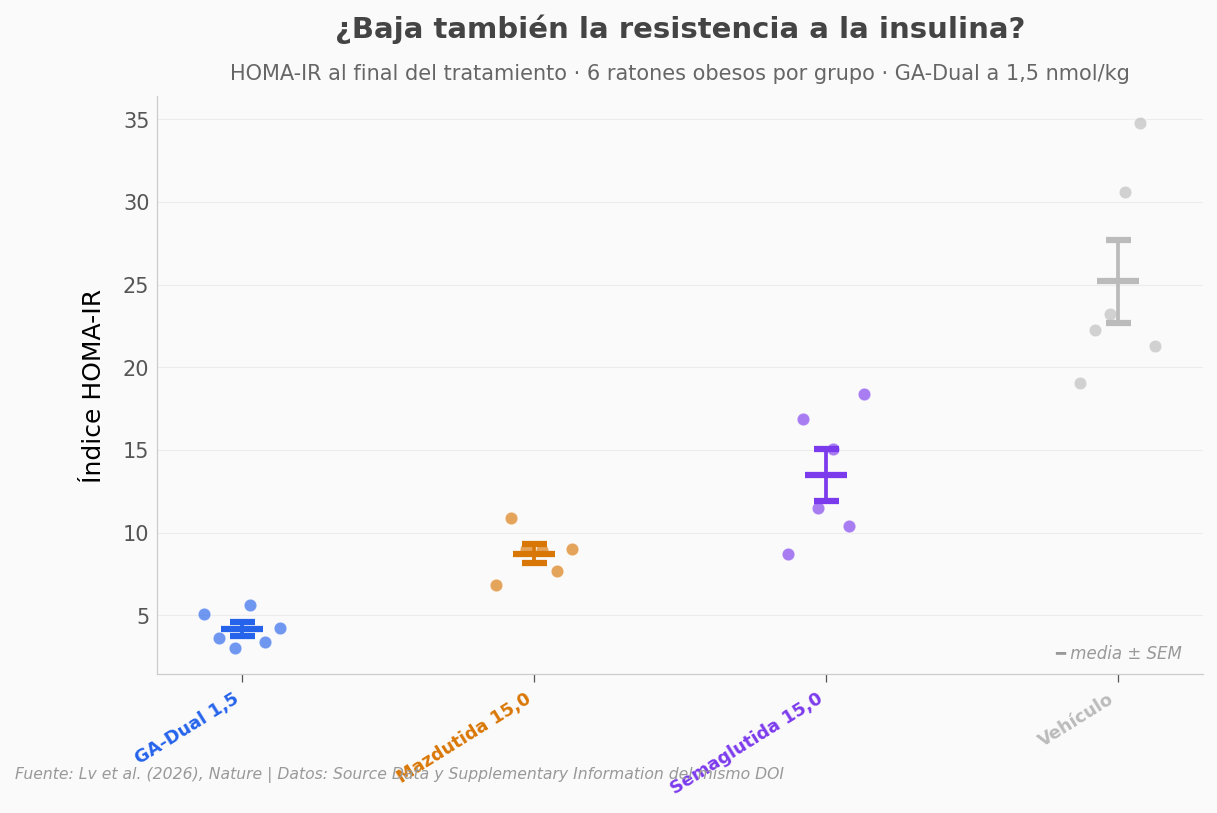

Orden por HOMA-IR (de menor a mayor): GA-Dual 1,5 < Mazdutida 15,0 < Semaglutida 15,0 < Vehículo
Orden por glucosa en ayunas:          GA-Dual 1,5 < Mazdutida 15,0 < Semaglutida 15,0 < Vehículo
¿Mismo orden? sí — con 4 grupos, coincidir es poco exigente: no es una correlación, es el mismo ranking
   GA-Dual 1,5        HOMA-IR   4,17 ± 1,01 (SD)
   Mazdutida 15,0     HOMA-IR   8,73 ± 1,37 (SD)
   Semaglutida 15,0   HOMA-IR  13,49 ± 3,85 (SD)
   Vehículo           HOMA-IR  25,19 ± 6,11 (SD)
GA-Dual 1,5 (n=6, media 4,17) vs Semaglutida 15,0 (n=6, media 13,49): diferencia −9,32 · d de Cohen −3,31 · Mann-Whitney p=0,0022
IC-Dual.P3 (n=5, media 107,97) vs anti-PD-1 (anticuerpo) (n=5, media 738,41): diferencia −630,44 · d de Cohen −1,49 · Mann-Whitney p=0,0159


In [7]:
# --- EXPERIMENTA AQUÍ ---
# Pregunta 2: ¿el HOMA-IR ordena los grupos igual que la glucosa en ayunas?
GRUPOS_HOMA = [g for g in GRUPOS_DIO if g in set(homa.tratamiento)]

fig, ax = plt.subplots(figsize=(9, 5))
strip_grupos(ax, homa, 'homa_ir', GRUPOS_HOMA, 'Índice HOMA-IR', '')
ax.set_title('¿Baja también la resistencia a la insulina?', fontsize=14, fontweight='bold', pad=28)
ax.text(0.5, 1.03, 'HOMA-IR al final del tratamiento · 6 ratones obesos por grupo · GA-Dual a 1,5 nmol/kg',
        transform=ax.transAxes, fontsize=10, color='#666666', ha='center')
fig.text(0.02, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/homa_ir.png', dpi=200, bbox_inches='tight')
plt.show()

orden_homa = homa.groupby('tratamiento').homa_ir.mean().sort_values()
orden_glu = glucosa.groupby('tratamiento').glucosa_ayunas_mmol_l.mean().sort_values()
pr('Orden por HOMA-IR (de menor a mayor):', ' < '.join(CORTO[g].replace(chr(10), ' ') for g in orden_homa.index))
pr('Orden por glucosa en ayunas:         ', ' < '.join(CORTO[g].replace(chr(10), ' ') for g in orden_glu.index))
pr('¿Mismo orden?', 'sí' if list(orden_homa.index) == list(orden_glu.index) else 'no',
   '— con 4 grupos, coincidir es poco exigente: no es una correlación, es el mismo ranking')
for g in GRUPOS_HOMA:
    v = homa[homa.tratamiento == g].homa_ir
    pr(f'   {CORTO[g].replace(chr(10), " "):18s} HOMA-IR {v.mean():6.2f} ± {v.std(ddof=1):.2f} (SD)')

# Compara cualquier par de grupos en cualquiera de los experimentos
def etiqueta(g):
    return CORTO.get(g, NOMBRE_TUMOR.get(g, g)).replace(chr(10), ' ')

def comparar(df, gcol, vcol, a, b):
    va = df[df[gcol] == a][vcol].values
    vb = df[df[gcol] == b][vcol].values
    pr(f'{etiqueta(a)} (n={len(va)}, media {va.mean():,.2f}) vs {etiqueta(b)} (n={len(vb)}, media {vb.mean():,.2f}):',
       f'diferencia {va.mean() - vb.mean():+,.2f} · d de Cohen {cohen_d(va, vb):.2f} · Mann-Whitney p={mw(va, vb):.4f}')

comparar(homa, 'tratamiento', 'homa_ir', GA_FIJO, 'Semaglutide (15.0 nmol/kg)')
comparar(t_fin, 'tratamiento', 'volumen_tumoral_mm3', 'IC-Dual.P3', 'Anti PD-1')

## Fuentes

**Paper**: [De novo design of high-potency dual-target therapeutic peptides with ORIDTP](https://doi.org/10.1038/s41586-026-11338-1)  
*Nature, 2026-11-25*

**Source Data**: [Source Data Figs. 2-5 and Source Data Extended Data Figs. 1-10 for "De novo design of high-potency dual-target therapeutic peptides with ORIDTP" (MOESM3)](https://static-content.springer.com/esm/art%3A10.1038%2Fs41586-026-11338-1/MediaObjects/41586_2026_11338_MOESM3_ESM.xlsx)  
*Nature, 2026-11-25*

**Supplementary Material**: [Supplementary Information for "De novo design of high-potency dual-target therapeutic peptides with ORIDTP" (MOESM1): Notes 1-7, 25 figures, 11 tables](https://static-content.springer.com/esm/art%3A10.1038%2Fs41586-026-11338-1/MediaObjects/41586_2026_11338_MOESM1_ESM.pdf)  
*Nature, 2026-11-25*

**Referencias citadas**: [Artificial intelligence for de novo design of dual-target peptides (pesos del modelo y datos de receptores)](https://doi.org/10.5281/zenodo.15597537)

*28 afirmaciones verificadas contra estas fuentes*

**Licencia de los datos:** material suplementario y Source Data de Springer Nature, reutilizados aquí para verificación científica.
**Código de este notebook:** [github.com/Ciencia-a-Mordiscos/lab](https://github.com/Ciencia-a-Mordiscos/lab) · **Canal:** [Ciencia a Mordiscos](https://www.youtube.com/@cienciaamordiscos)